In [1]:
from tqdm.auto import tqdm
import torch
from torch import nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import models
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
import numpy as np
import os

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
import os
root = "/kaggle/input/datasets/ahmedmohamed365/volleyball/volleyball_/videos"

data = []

for video_folder_name in os.listdir(root):
    current_video_folder_path = os.path.join(root, video_folder_name)

    if not os.path.isdir(current_video_folder_path):
        continue

    annotations_path = os.path.join(current_video_folder_path, "annotations.txt")

    if not os.path.isfile(annotations_path):
        continue

    # Pre-calculate video ID once per folder
    vid_id = int(video_folder_name)

    with open(annotations_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 2:
                image_filename = parts[0]
                activity = parts[1]
                name_folder = image_filename.split('.')[0]
                image_path = f"{current_video_folder_path}/{name_folder}/{image_filename}"

                data.append([vid_id, image_path, activity])

In [4]:
train_videos = [1, 3, 6, 7, 10, 13, 15, 16, 18, 22, 23, 31,32, 36, 38, 39, 40, 41, 42, 48, 50, 52, 53, 54]
val_videos = [0, 2, 8, 12, 17, 19, 24, 26, 27, 28, 30, 33,46, 49, 51]
test_videos = [4, 5, 9, 11, 14, 20, 21, 25, 29, 34, 35, 37,43, 44, 45, 47]

# Convert video lists to sets for efficient lookups
train_videos_set = set(train_videos)
val_videos_set = set(val_videos)
test_videos_set = set(test_videos)

train_data = []
val_data = []
test_data = []

# Populate the data lists in a single pass
for video_id, image_path, activity in data:
    if video_id in train_videos_set:
        train_data.append([image_path, activity])
    elif video_id in val_videos_set:
        val_data.append([image_path, activity])
    elif video_id in test_videos_set:
        test_data.append([image_path, activity])

In [5]:
label_encoder = LabelEncoder()

all_activities = [item[2] for item in data]
label_encoder.fit(all_activities)

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [6]:
class CustomImageDataset(Dataset):
    def __init__(self, data, transform=None, label_encoder=None):
        self.image_paths = [item[0] for item in data]
        self.transform = transform
        
        raw_labels = [item[1] for item in data]
        if label_encoder is not None:
            self.labels = torch.as_tensor(label_encoder.transform(raw_labels), dtype=torch.long)
        else:
            self.labels = torch.as_tensor(LabelEncoder().fit_transform(raw_labels), dtype=torch.long)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            image = self.transform(image)

        return image, self.labels[idx]
     

In [7]:
train_dataset = CustomImageDataset(data=train_data, transform=transform, label_encoder=label_encoder)
val_dataset = CustomImageDataset(data=val_data, transform=transform, label_encoder=label_encoder)
test_dataset = CustomImageDataset(data=test_data, transform=transform, label_encoder=label_encoder)

In [8]:
LR = 1e-3
BATCH_SIZE = 128
EPOCHS = 100

In [9]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

In [10]:
model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    8
)
model = nn.DataParallel(model)
model = model.to(device)

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6 
)

In [12]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []

best_val_loss = float("inf")
patience = 5
counter = 0

for epoch in range(EPOCHS):
    total_acc_train = total_loss_train = total_loss_val = total_acc_val = 0
    seen_train = seen_val = 0

    model.train()
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]", leave=False)
    for inputs, labels in train_bar:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(inputs)
        train_loss = criterion(outputs, labels)
        total_loss_train += train_loss.item()
        train_loss.backward()
        optimizer.step()

        batch_correct = (torch.argmax(outputs, 1) == labels).sum().item()
        total_acc_train += batch_correct
        seen_train += labels.size(0)

        train_bar.set_postfix(
            loss=f"{train_loss.item():.4f}",
            acc=f"{total_acc_train / seen_train * 100:.2f}%",
        )

    model.eval()
    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [val]", leave=False)
    with torch.no_grad():
        for inputs, labels in val_bar:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)
            val_loss = criterion(outputs, labels)
            total_loss_val += val_loss.item()

            batch_correct = (torch.argmax(outputs, 1) == labels).sum().item()
            total_acc_val += batch_correct
            seen_val += labels.size(0)

            val_bar.set_postfix(
                loss=f"{val_loss.item():.4f}",
                acc=f"{total_acc_val / seen_val * 100:.2f}%",
            )

    avg_train_loss = total_loss_train / len(train_loader)
    avg_val_loss = total_loss_val / len(val_loader)
    scheduler.step()

    total_loss_train_plot.append(round(avg_train_loss, 4))
    total_loss_validation_plot.append(round(avg_val_loss, 4))
    total_acc_train_plot.append(round(total_acc_train / seen_train * 100, 4))
    total_acc_validation_plot.append(round(total_acc_val / seen_val * 100, 4))

    print(
        f"Epoch {epoch + 1}/{EPOCHS}, "
        f"Train Loss: {avg_train_loss:.4f} "
        f"Train Accuracy: {total_acc_train / seen_train * 100:.2f}% "
        f"Validation Loss: {avg_val_loss:.4f} "
        f"Validation Accuracy: {total_acc_val / seen_val * 100:.2f}%"
    )
    print("=" * 25)

Epoch 1/100 [train]:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch 1/100 [val]:   0%|          | 0/11 [00:00<?, ?it/s]

Epoch 1/100, Train Loss: 1.7698 Train Accuracy: 32.25% Validation Loss: 2.7795 Validation Accuracy: 27.89%


Epoch 2/100 [train]:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch 2/100 [val]:   0%|          | 0/11 [00:00<?, ?it/s]

...

Epoch 99/100 [val]:   0%|          | 0/11 [00:00<?, ?it/s]

Epoch 99/100, Train Loss: 0.0000 Train Accuracy: 100.00% Validation Loss: 2.0461 Validation Accuracy: 66.29%


Epoch 100/100 [train]:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch 100/100 [val]:   0%|          | 0/11 [00:00<?, ?it/s]

Epoch 100/100, Train Loss: 0.0000 Train Accuracy: 100.00% Validation Loss: 2.0363 Validation Accuracy: 66.74%


In [13]:
model.eval()
with torch.no_grad():
    total_acc_test = 0
    for inputs, labels in test_loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        predictions = model(inputs)
        acc = (torch.argmax(predictions, axis=1) == labels).sum().item()
        total_acc_test += acc
test_accuracy = (total_acc_test / len(test_dataset)) * 100
print(f"Accuracy Score is: "f"{test_accuracy:.2f}%")

Accuracy Score is: 70.61%


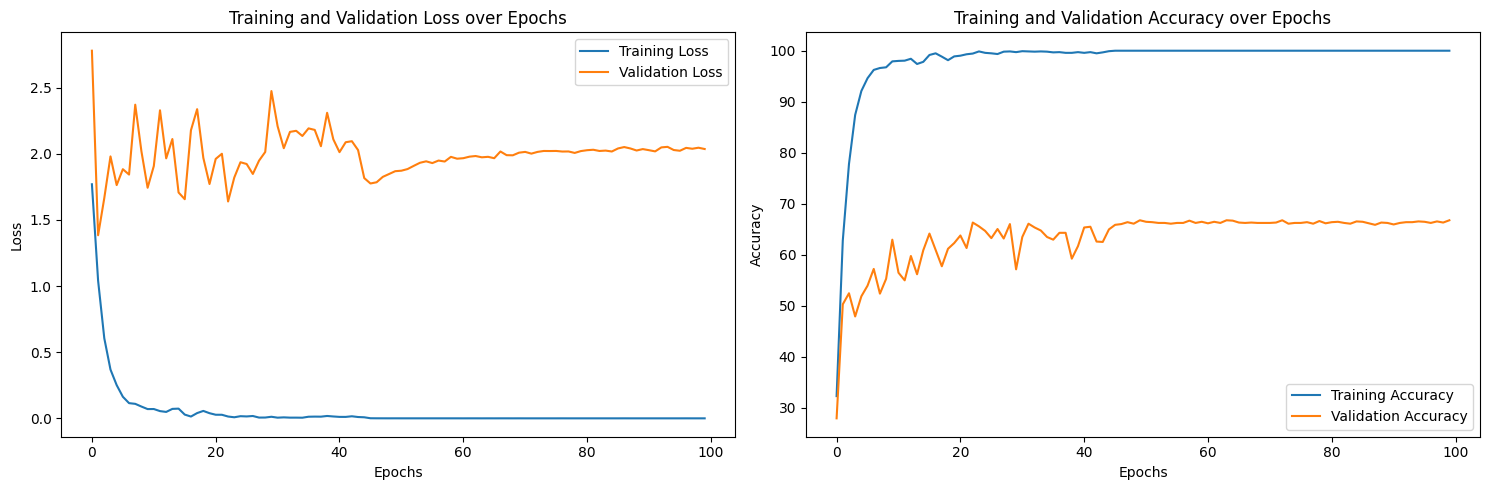

In [14]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

axs[0].plot(total_loss_train_plot, label='Training Loss')
axs[0].plot(total_loss_validation_plot, label='Validation Loss')
axs[0].set_title('Training and Validation Loss over Epochs')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend()

axs[1].plot(total_acc_train_plot, label='Training Accuracy')
axs[1].plot(total_acc_validation_plot, label='Validation Accuracy')
axs[1].set_title('Training and Validation Accuracy over Epochs')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend()

plt.tight_layout()

plt.show()